In [ ]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scvelo
import yaml
from scipy import stats
from tqdm import tqdm
from velotest.hypothesis_testing import run_hypothesis_test_on
from velotest.neighbors import find_neighbors, find_neighbors_in_direction_of_velocity


In [17]:
datasets = {
        "Pancreas_dynamical": "/mnt/volume/Johanna_Velotest/configs/pancreas_dynamic.yaml",
        "Pancreas_stochastic": "/mnt/volume/Johanna_Velotest/configs/pancreas_stochastic.yaml",
        "Dentate_gyrus": "/mnt/volume/Johanna_Velotest/configs/dentategyrus.yaml",
        "Gastrulation_erythroid": "/mnt/volume/Johanna_Velotest/configs/gastrulation.yaml",
        "Bone_marrow": "/mnt/volume/Johanna_Velotest/configs/bonemarrow.yaml",
        "PBMC": "/mnt/volume/Johanna_Velotest/configs/pbmc.yaml",
        "Covid": "/mnt/volume/Johanna_Velotest/configs/covid.yaml",
        "Retinal_development": "/mnt/volume/Johanna_Velotest/configs/retinal_development.yaml",
        "Human_HSC": "/mnt/volume/Johanna_Velotest/configs/humanHSC.yaml",
        "RPE_1": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/intestinal_organoids.yaml",
        "Hindbrain_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/hindbrain.yaml",
        "Oligodendrocyte_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/oligodendrocyte.yaml",
        "Bone_marrow_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/mouse_bonemarrow.yaml",
        "Cerebral_cortex_human": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/human_cerebral.yaml",
        "Hematopoiesis_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/mouse_hema.yaml",
        "Spermatogenisis": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/spermatogenesis.yaml",
        "Old_brain": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/old_brain.yaml",
        "Prefrontal_cortex": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/pfc.yaml",
        "Intestinal_organoids":"/mnt/volume/Johanna_Velotest/configs/noEmbedding/GSE128365.yaml",
        "Zebra_NMP": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/zebra_NMP.yaml"
    }

cell = {}
gene = {}
for name, path in datasets.items():
    with open(path, "r") as f:
            config = yaml.safe_load(f)
   
    adata = sc.read(config["path"]) 
    cell[name] = adata.n_obs
    gene[name] = np.sum(adata.var.velocity_genes)

    print(f"{name}: {adata.n_obs} cells; {np.sum(adata.var.velocity_genes)} velocity genes")
count_df = pd.DataFrame(list(cell.items()), columns=['Dataset', 'CellCount'])
gene_df = pd.DataFrame(list(cell.items()), columns=['Dataset', 'VelocityGenes'])

Pancreas_dynamical: 3696 cells; 1027 velocity genes
Pancreas_stochastic: 3696 cells; 1038 velocity genes
Dentate_gyrus: 2930 cells; 557 velocity genes
Gastrulation_erythroid: 9815 cells; 488 velocity genes
Bone_marrow: 5780 cells; 451 velocity genes
PBMC: 65877 cells; 12 velocity genes
Covid: 3076 cells; 126 velocity genes
Retinal_development: 2726 cells; 677 velocity genes
Human_HSC: 11605 cells; 328 velocity genes
RPE_1: 5422 cells; 387 velocity genes
Hindbrain_mouse: 13501 cells; 288 velocity genes
Oligodendrocyte_mouse: 36146 cells; 384 velocity genes
Bone_marrow_mouse: 2600 cells; 592 velocity genes
Cerebral_cortex_human: 4693 cells; 351 velocity genes
Hematopoiesis_mouse: 1772 cells; 1218 velocity genes
Spermatogenisis: 1829 cells; 299 velocity genes
Old_brain: 1823 cells; 1302 velocity genes
Prefrontal_cortex: 1267 cells; 1232 velocity genes
Intestinal_organoids: 3831 cells; 156 velocity genes
Zebra_NMP: 16035 cells; 897 velocity genes


In [30]:
# Load all datasets
pca_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/Wasserstein_PCA.csv")
tsne10_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/Wasserstein_tSNE_p10.csv")
tsne30_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/Wasserstein_tSNE_p30.csv")
tsne50_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/Wasserstein_tSNE_p50.csv")
umap10_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/Wasserstein_UMAP_n10.csv")
umap30_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/Wasserstein_UMAP_n30.csv")
umap50_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/Wasserstein_UMAP_n50.csv")
umap100_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/Wasserstein_UMAP_n100.csv")
veloviz_values = pd.read_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/Wasserstein_veloviz.csv")
tsne_2000cells = pd.read_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/Wasserstein_tSNE_subsampled_2000cells.csv")
tsne_mid_cluster = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/cluster_subsample/Wasserstein_tSNE_middle_cluster.csv")
tsne_high_cluster = pd.read_csv("/mnt/volume/Johanna_Velotest/results/distances/cluster_subsample/Wasserstein_tSNE_high_cluster.csv")

## Plot the general differences tSNE, UMAP, VeloViz

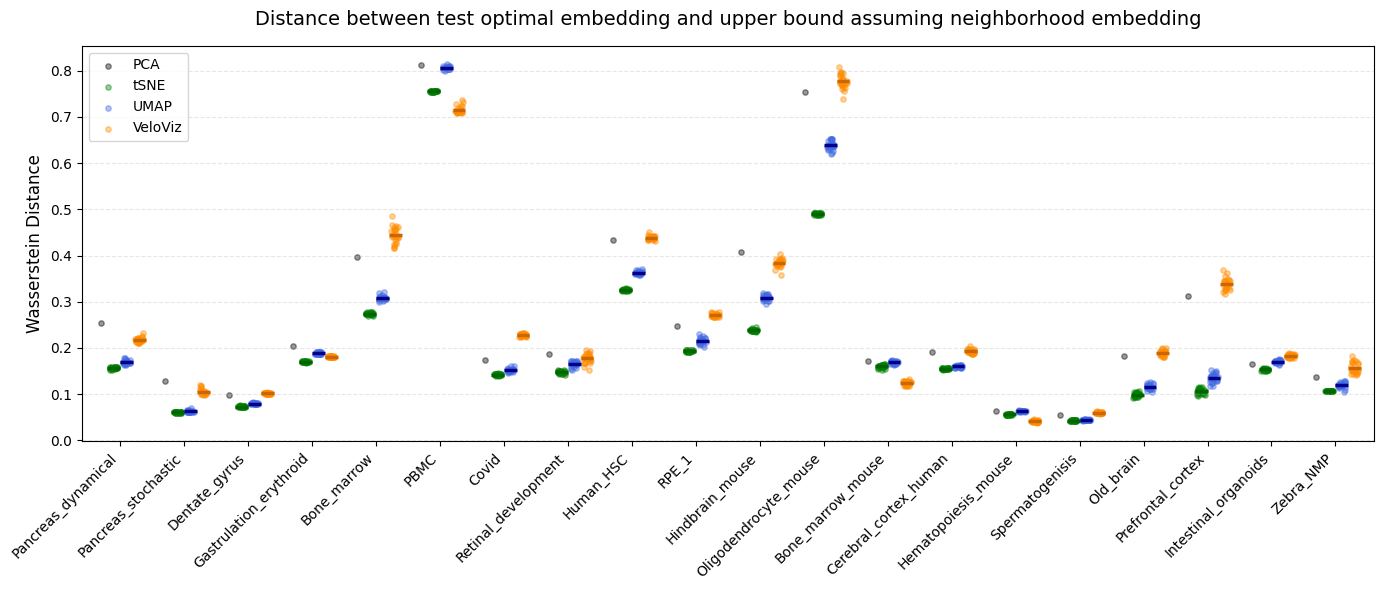

In [5]:
plotset= {}

for name, path in datasets.items():
    with open(path, "r") as f:
        config = yaml.safe_load(f)

    plotset[name] = {
        'pca': pca_values[name].values,
        'tsne': tsne30_values[name].values,
        'umap': umap30_values[name].values,
        'veloviz': veloviz_values[name].values
    }

fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

offsets = {'pca': -0.3, 'tsne': -0.1, 'umap': 0.1, 'veloviz': 0.3}
colors = {'pca': 'black', 'tsne': 'green', 'umap': 'royalblue', 'veloviz': 'darkorange'}

# Dictionary to catch one of each handle for a clean legend
legend_elements = {}

for i, name in enumerate(plotset):
    d = plotset[name]

    # Plot PCA
    x_pca = i + offsets['pca']
    h_pca = ax.scatter(x_pca, d['pca'], color=colors['pca'], alpha=0.4, s=15)
    if 'PCA' not in legend_elements: 
        legend_elements['PCA'] = h_pca

    # Plot tSNE
    x_tsne = i + offsets['tsne']
    h_tsne = ax.scatter(add_jitter(x_tsne, d['tsne']), d['tsne'], color=colors['tsne'], alpha=0.4, s=15)
    h_mean = ax.hlines(np.mean(d['tsne']), x_tsne-0.1, x_tsne+0.1, color='darkgreen', linewidth=2.5)
    if 'tSNE Random Init' not in legend_elements: 
        legend_elements['tSNE'] = h_tsne

    # Plot UMAP 
    x_umap = i + offsets['umap']
    h_umap = ax.scatter(add_jitter(x_umap, d['umap']), d['umap'], color=colors['umap'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['umap']), x_umap-0.1, x_umap+0.1, color='darkblue', linewidth=2.5)
    if 'UMAP Random Init' not in legend_elements: 
        legend_elements['UMAP'] = h_umap

    # Plot veloviz
    x_velo = i + offsets['veloviz']
    h_velo = ax.scatter(add_jitter(x_velo, d['veloviz']), d['veloviz'], color=colors['veloviz'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['veloviz']), x_velo-0.1, x_velo+0.1, color='#cc6600', linewidth=2.5)
    if 'VeloViz' not in legend_elements: 
        legend_elements['VeloViz'] = h_velo


# Set x-ticks exactly at the integer positions for the datasets
ax.set_xticks(range(len(plotset)))
ax.set_xticklabels(plotset, rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(plotset) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Wasserstein Distance", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding", fontsize=14, pad=15)

# Build custom legend using our deduplicated handles
# Placed slightly outside the plot area to prevent overlapping the 8 datasets
ax.legend(legend_elements.values(), legend_elements.keys(), 
        loc='upper left')

plt.tight_layout()
#plt.savefig("results/Wasserstein_UMAP_TSNE.pdf", transparent=True)
plt.show()

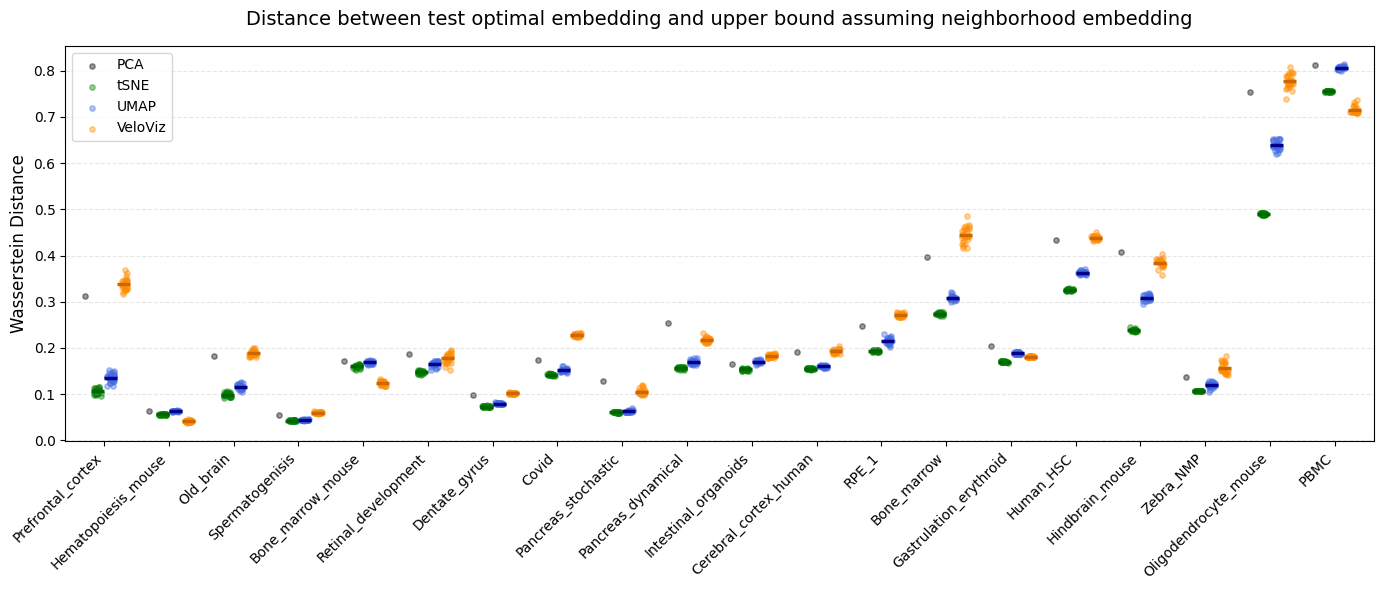

In [6]:
plotset= {}

for name, path in datasets.items():
    plotset[name] = {
        'pca': pca_values[name].values,
        'tsne': tsne30_values[name].values,
        'umap': umap30_values[name].values,
        'veloviz': veloviz_values[name].values
    }

sorted_dataset_names = count_df.sort_values(by='CellCount')['Dataset'].tolist()

fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

offsets = {'pca': -0.3, 'tsne': -0.1, 'umap': 0.1, 'veloviz': 0.3}
colors = {'pca': 'black', 'tsne': 'green', 'umap': 'royalblue', 'veloviz': 'darkorange'}

# Dictionary to catch one of each handle for a clean legend
legend_elements = {}

for i, name in enumerate(sorted_dataset_names):
    d = plotset[name]

    # Plot PCA
    x_pca = i + offsets['pca']
    h_pca = ax.scatter(x_pca, d['pca'], color=colors['pca'], alpha=0.4, s=15)
    if 'PCA' not in legend_elements: 
        legend_elements['PCA'] = h_pca

    # Plot tSNE
    x_tsne = i + offsets['tsne']
    h_tsne = ax.scatter(add_jitter(x_tsne, d['tsne']), d['tsne'], color=colors['tsne'], alpha=0.4, s=15)
    h_mean = ax.hlines(np.mean(d['tsne']), x_tsne-0.1, x_tsne+0.1, color='darkgreen', linewidth=2.5)
    if 'tSNE Random Init' not in legend_elements: 
        legend_elements['tSNE'] = h_tsne

    # Plot UMAP 
    x_umap = i + offsets['umap']
    h_umap = ax.scatter(add_jitter(x_umap, d['umap']), d['umap'], color=colors['umap'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['umap']), x_umap-0.1, x_umap+0.1, color='darkblue', linewidth=2.5)
    if 'UMAP Random Init' not in legend_elements: 
        legend_elements['UMAP'] = h_umap

    # Plot veloviz
    x_velo = i + offsets['veloviz']
    h_velo = ax.scatter(add_jitter(x_velo, d['veloviz']), d['veloviz'], color=colors['veloviz'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['veloviz']), x_velo-0.1, x_velo+0.1, color='#cc6600', linewidth=2.5)
    if 'VeloViz' not in legend_elements: 
        legend_elements['VeloViz'] = h_velo


# Set x-ticks exactly at the integer positions for the datasets
ax.set_xticks(range(len(sorted_dataset_names)))
ax.set_xticklabels(sorted_dataset_names, rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(sorted_dataset_names) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Wasserstein Distance", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding", fontsize=14, pad=15)

# Build custom legend using our deduplicated handles
# Placed slightly outside the plot area to prevent overlapping the 8 datasets
ax.legend(legend_elements.values(), legend_elements.keys(), 
        loc='upper left')

plt.tight_layout()
#plt.savefig("results/Wasserstein_UMAP_Neighbors.pdf", transparent=True)
plt.show()

## Plot different parameters tSNE, UMAP

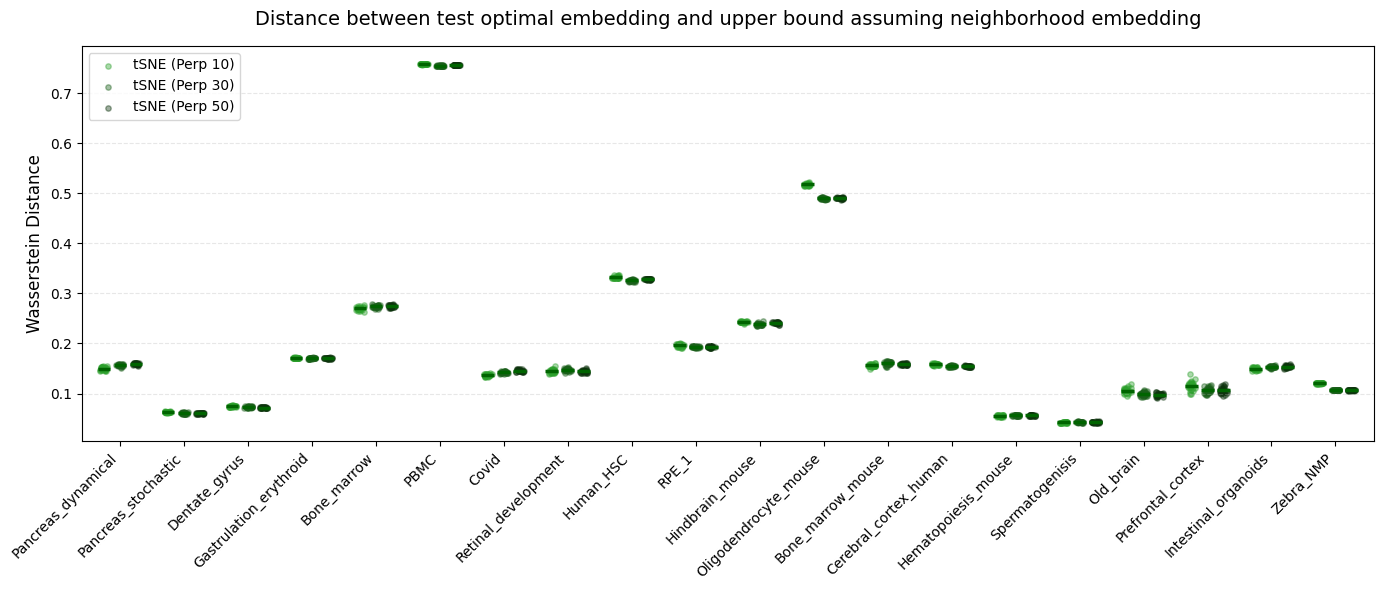

In [7]:
plotset= {}

for name, path in datasets.items():
    plotset[name] = {
        'tsne_10': tsne10_values[name].values,
        'tsne_30': tsne30_values[name].values,
        'tsne_50': tsne50_values[name].values
    }


fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

offsets = {'tsne_10': -0.25, 'tsne_30': 0.0, 'tsne_50': 0.25}
colors = {'tsne_10': '#2ca02c', 'tsne_30': '#1a5f1a', 'tsne_50': '#0d330d'}

# Dictionary to catch one of each handle for a clean legend
legend_elements = {}

for i, name in enumerate(plotset):
    d = plotset[name]

    # Plot tSNE 10
    x_tsne_10 = i + offsets['tsne_10']
    h_tsne_10 = ax.scatter(add_jitter(x_tsne_10, d['tsne_10']), d['tsne_10'], color=colors['tsne_10'], alpha=0.4, s=15)
    h_mean_10 = ax.hlines(np.mean(d['tsne_10']), x_tsne_10-0.1, x_tsne_10+0.1, color='darkgreen', linewidth=2.5)
    if 'tSNE (Perp 10)' not in legend_elements: 
        legend_elements['tSNE (Perp 10)'] = h_tsne_10


    # Plot tSNE 30
    x_tsne_30 = i + offsets['tsne_30']
    h_tsne_30 = ax.scatter(add_jitter(x_tsne_30, d['tsne_30']), d['tsne_30'], color=colors['tsne_30'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['tsne_30']), x_tsne_30-0.1, x_tsne_30+0.1, color='darkgreen', linewidth=2.5)
    if 'tSNE (Perp 30)' not in legend_elements: 
        legend_elements['tSNE (Perp 30)'] = h_tsne_30

    # Plot tSNE 50
    x_tsne_50 = i + offsets['tsne_50']
    h_tsne_50 = ax.scatter(add_jitter(x_tsne_50, d['tsne_50']), d['tsne_50'], color=colors['tsne_50'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['tsne_50']), x_tsne_50-0.1, x_tsne_50+0.1, color='darkgreen', linewidth=2.5)
    if 'tSNE (Perp 50)' not in legend_elements: 
        legend_elements['tSNE (Perp 50)'] = h_tsne_50


# Set x-ticks exactly at the integer positions for the datasets
ax.set_xticks(range(len(plotset)))
ax.set_xticklabels(plotset, rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(plotset) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Wasserstein Distance", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding", fontsize=14, pad=15)

# Build custom legend using our deduplicated handles
# Placed slightly outside the plot area to prevent overlapping the 8 datasets
ax.legend(legend_elements.values(), legend_elements.keys(), 
        loc='upper left')

plt.tight_layout()
#plt.savefig("results/Wasserstein_UMAP_TSNE.pdf", transparent=True)
plt.show()

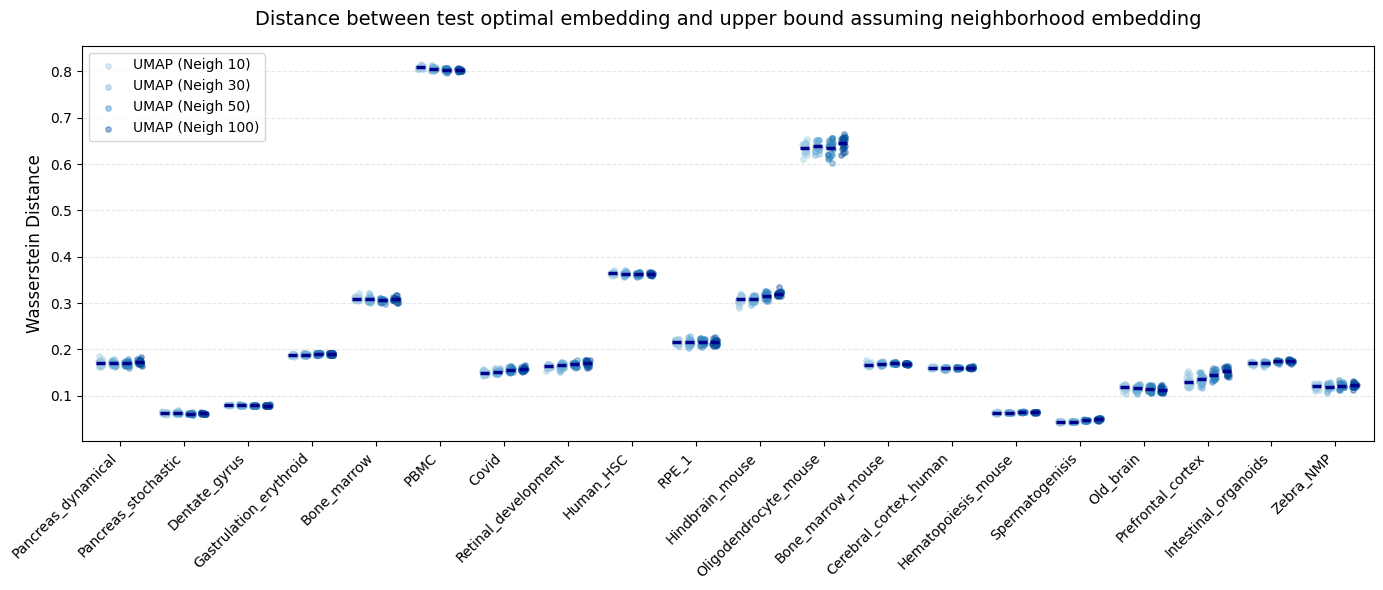

In [8]:
plotset= {}

for name, path in datasets.items():
    plotset[name] = {
        'umap_10': umap10_values[name].values,
        'umap_30': umap30_values[name].values,
        'umap_50': umap50_values[name].values,
        'umap_100': umap100_values[name].values,
    }

fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.04):
    return x_base + np.random.uniform(-width, width, size=len(arr))

offsets = {'umap_10': -0.3, 'umap_30': -0.1, 'umap_50': 0.1, 'umap_100': 0.3}
colors = {'umap_10': '#9ecae1', 'umap_30': '#6baed6', 'umap_50': '#3182bd', 'umap_100': '#08519c'}

# Dictionary to catch one of each handle for a clean legend
legend_elements = {}

for i, name in enumerate(plotset):
    d = plotset[name]

    # Plot UMAP 10
    x_umap_10 = i + offsets['umap_10']
    h_umap_10 = ax.scatter(add_jitter(x_umap_10, d['umap_10']), d['umap_10'], color=colors['umap_10'], alpha=0.4, s=15)
    h_mean_10 = ax.hlines(np.mean(d['umap_10']), x_umap_10-0.07, x_umap_10+0.07, color='darkblue', linewidth=2.5)
    if 'UMAP (Neigh 10)' not in legend_elements: 
        legend_elements['UMAP (Neigh 10)'] = h_umap_10

    # Plot UMAP 30
    x_umap_30 = i + offsets['umap_30']
    h_umap_30 = ax.scatter(add_jitter(x_umap_30, d['umap_30']), d['umap_30'], color=colors['umap_30'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['umap_30']), x_umap_30-0.07, x_umap_30+0.07, color='darkblue', linewidth=2.5)
    if 'UMAP (Neigh 30)' not in legend_elements: 
        legend_elements['UMAP (Neigh 30)'] = h_umap_30

    # Plot UMAP 50
    x_umap_50 = i + offsets['umap_50']
    h_umap_50 = ax.scatter(add_jitter(x_umap_50, d['umap_50']), d['umap_50'], color=colors['umap_50'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['umap_50']), x_umap_50-0.07, x_umap_50+0.07, color='darkblue', linewidth=2.5)
    if 'UMAP (Neigh 50)' not in legend_elements: 
        legend_elements['UMAP (Neigh 50)'] = h_umap_50

    # Plot UMAP 100
    x_umap_100 = i + offsets['umap_100']
    h_umap_100 = ax.scatter(add_jitter(x_umap_100, d['umap_100']), d['umap_100'], color=colors['umap_100'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['umap_100']), x_umap_100-0.07, x_umap_100+0.07, color='darkblue', linewidth=2.5)
    if 'UMAP (Neigh 100)' not in legend_elements: 
        legend_elements['UMAP (Neigh 100)'] = h_umap_100


# Set x-ticks exactly at the integer positions for the datasets
ax.set_xticks(range(len(plotset)))
ax.set_xticklabels(plotset, rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(plotset) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Wasserstein Distance", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding", fontsize=14, pad=15)

# Build custom legend using our deduplicated handles
# Placed slightly outside the plot area to prevent overlapping the 8 datasets
ax.legend(legend_elements.values(), legend_elements.keys(), 
        loc='upper left')

plt.tight_layout()
#plt.savefig("results/Wasserstein_UMAP_Neighbors.pdf", transparent=True)
plt.show()

## Plot different subsettings (to 2.000 cells, highest or middle cluster)

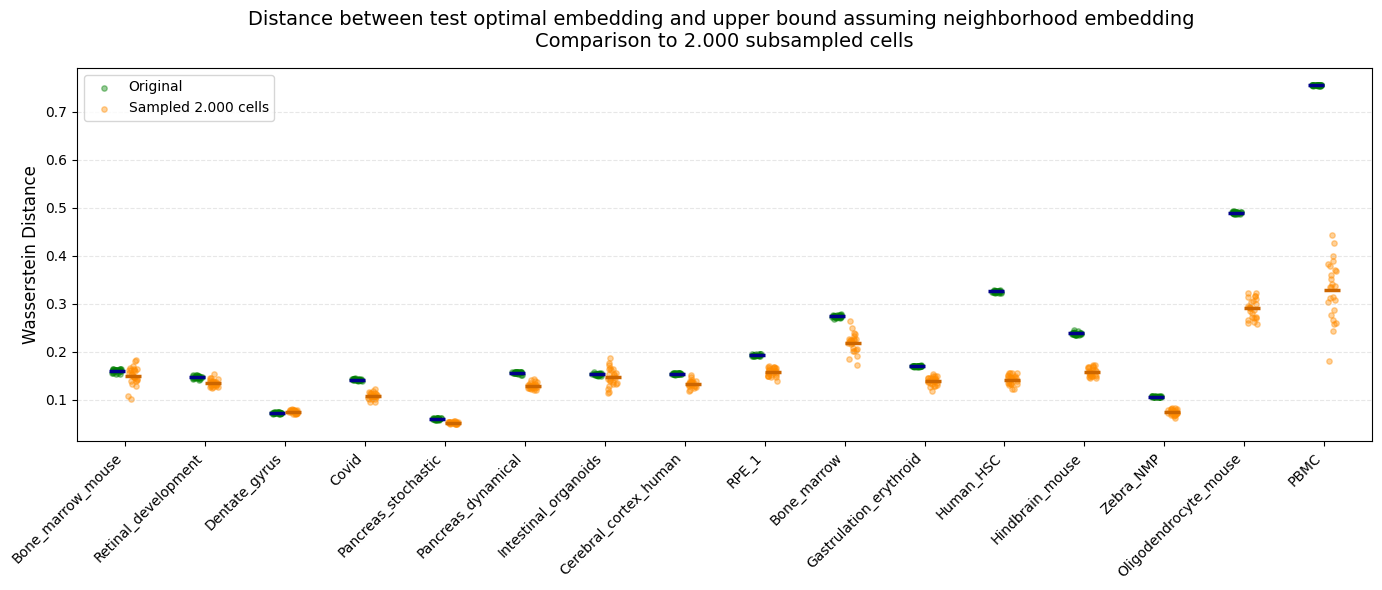

In [35]:
plotset= {}

for name, path in datasets.items():
    if cell[name] < 2000:
        continue
    plotset[name] = {
        'tsne': tsne30_values[name].values,
        'samp': tsne_2000cells[name].values
    }

df = pd.merge(count_df, gene_df, on='Dataset')
filtered_df = df[df['CellCount'] >= 2000]
sorted_dataset_names = filtered_df.sort_values(by='CellCount')['Dataset'].tolist()

fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

offsets = {'tsne': -0.1, 'umap': 0.0, 'samp': 0.1}
colors = {'tsne': 'green', 'umap': 'royalblue', 'samp': 'darkorange'}

# Dictionary to catch one of each handle for a clean legend
legend_elements = {}

for i, name in enumerate(sorted_dataset_names):
    d = plotset[name]

    # Plot tSNE
    x_tsne = i + offsets['tsne']
    h_tsne = ax.scatter(add_jitter(x_tsne, d['tsne']), d['tsne'], color=colors['tsne'], alpha=0.4, s=15)
    h_mean = ax.hlines(np.mean(d['tsne']), x_tsne-0.1, x_tsne+0.1, color='darkblue', linewidth=2.5)
    if 'tSNE Random Init' not in legend_elements: 
        legend_elements['Original'] = h_tsne

    # Plot sampled
    x_velo = i + offsets['samp']
    h_velo = ax.scatter(add_jitter(x_velo, d['samp']), d['samp'], color=colors['samp'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['samp']), x_velo-0.1, x_velo+0.1, color='#cc6600', linewidth=2.5)
    if 'Sampled' not in legend_elements: 
        legend_elements['Sampled 2.000 cells'] = h_velo


# Set x-ticks exactly at the integer positions for the datasets
ax.set_xticks(range(len(sorted_dataset_names)))
ax.set_xticklabels(sorted_dataset_names, rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(sorted_dataset_names) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Wasserstein Distance", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding \nComparison to 2.000 subsampled cells", fontsize=14, pad=15)

# Build custom legend using our deduplicated handles
# Placed slightly outside the plot area to prevent overlapping the 8 datasets
ax.legend(legend_elements.values(), legend_elements.keys(), 
        loc='upper left')

plt.tight_layout()
#plt.savefig("results/Wasserstein_UMAP_Neighbors.pdf", transparent=True)
plt.show()

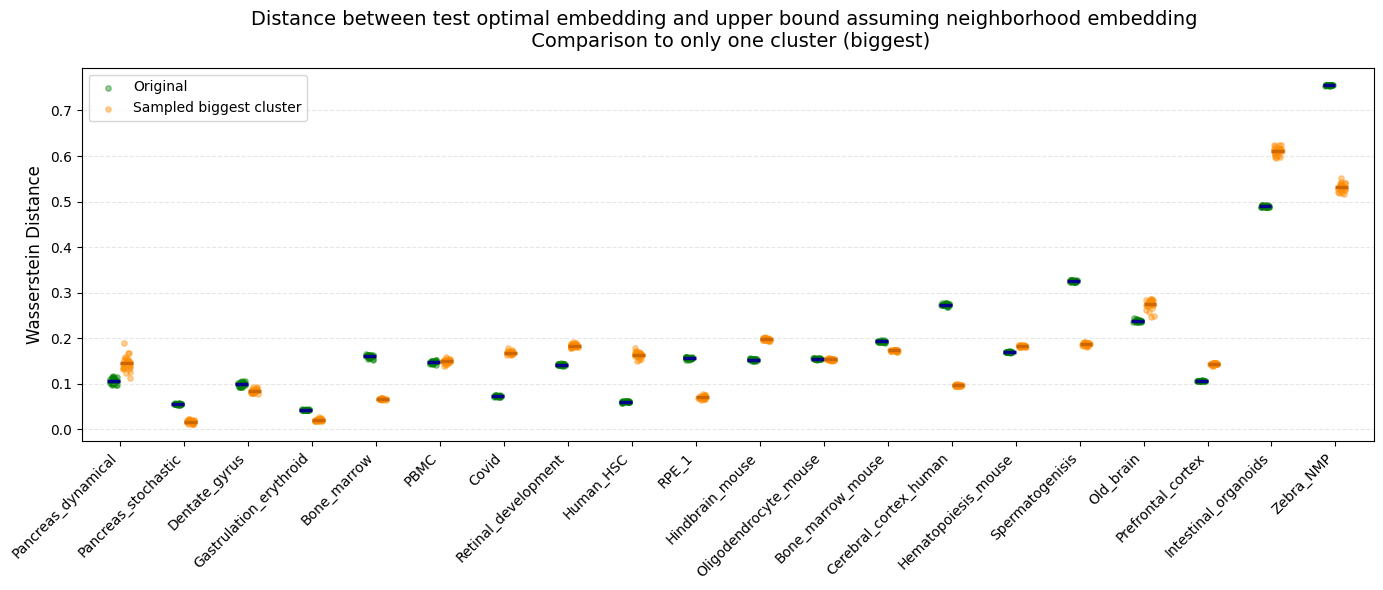

In [36]:

plotset = {}

for name, path in datasets.items():
    new_data_row = tsne_high_cluster[tsne_high_cluster['dataset_name'] == name]
    
    if name in tsne30_values and not new_data_row.empty:
        raw_distances = new_data_row['distances'].iloc[0]
        
        # Get distance array
        if isinstance(raw_distances, str):
            float_strings = re.findall(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?', raw_distances)
            samp_array = np.array([float(x) for x in float_strings])
        else:
            samp_array = np.array(raw_distances)

        plotset[name] = {
            'tsne': tsne30_values[name].values,
            'samp': samp_array
        }

sorted_dataset_names = count_df.sort_values(by='CellCount')['Dataset'].tolist()

fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

offsets = {'tsne': -0.1, 'umap': 0.0, 'samp': 0.1}
colors = {'tsne': 'green', 'umap': 'royalblue', 'samp': 'darkorange'}

# Dictionary to catch one of each handle for a clean legend
legend_elements = {}

for i, name in enumerate(sorted_dataset_names):
    d = plotset[name]

    # Plot Original tSNE
    x_tsne = i + offsets['tsne']
    h_tsne = ax.scatter(add_jitter(x_tsne, d['tsne']), d['tsne'], color=colors['tsne'], alpha=0.4, s=15)
    h_mean = ax.hlines(np.mean(d['tsne']), x_tsne-0.1, x_tsne+0.1, color='darkblue', linewidth=2.5)
    if 'Original' not in legend_elements: 
        legend_elements['Original'] = h_tsne

    # Plot Subsampled
    x_velo = i + offsets['samp']
    h_velo = ax.scatter(add_jitter(x_velo, d['samp']), d['samp'], color=colors['samp'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['samp']), x_velo-0.1, x_velo+0.1, color='#cc6600', linewidth=2.5)
    if 'Sampled biggest cluster' not in legend_elements: 
        legend_elements['Sampled biggest cluster'] = h_velo

# Set x-ticks exactly at the integer positions for the datasets
ax.set_xticks(range(len(plotset)))
ax.set_xticklabels(plotset, rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(plotset) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Wasserstein Distance", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding \n Comparison to only one cluster (biggest)", fontsize=14, pad=15)

# Build custom legend using our deduplicated handles
ax.legend(legend_elements.values(), legend_elements.keys(), loc='upper left')

plt.tight_layout()
# plt.savefig("results/Wasserstein_UMAP_Neighbors.pdf", transparent=True)
plt.show()


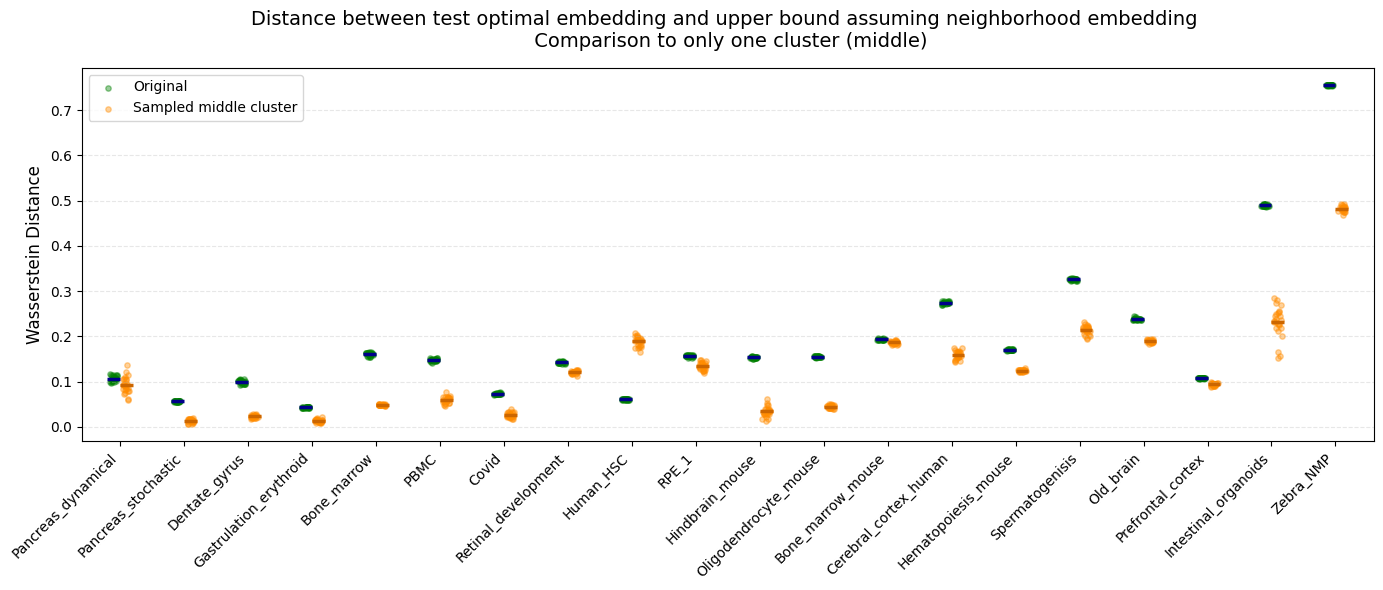

In [37]:
plotset = {}

for name, path in datasets.items():
    new_data_row = tsne_mid_cluster[tsne_mid_cluster['dataset_name'] == name]
    
    if name in tsne30_values and not new_data_row.empty:
        raw_distances = new_data_row['distances'].iloc[0]
        
        # Get distance array
        if isinstance(raw_distances, str):
            float_strings = re.findall(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?', raw_distances)
            samp_array = np.array([float(x) for x in float_strings])
        else:
            samp_array = np.array(raw_distances)

        plotset[name] = {
            'tsne': tsne30_values[name].values,
            'samp': samp_array
        }

sorted_dataset_names = count_df.sort_values(by='CellCount')['Dataset'].tolist()

fig, ax = plt.subplots(figsize=(14, 6))

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

offsets = {'tsne': -0.1, 'umap': 0.0, 'samp': 0.1}
colors = {'tsne': 'green', 'umap': 'royalblue', 'samp': 'darkorange'}

# Dictionary to catch one of each handle for a clean legend
legend_elements = {}

for i, name in enumerate(sorted_dataset_names):
    d = plotset[name]

    # Plot Original tSNE
    x_tsne = i + offsets['tsne']
    h_tsne = ax.scatter(add_jitter(x_tsne, d['tsne']), d['tsne'], color=colors['tsne'], alpha=0.4, s=15)
    h_mean = ax.hlines(np.mean(d['tsne']), x_tsne-0.1, x_tsne+0.1, color='darkblue', linewidth=2.5)
    if 'Original' not in legend_elements: 
        legend_elements['Original'] = h_tsne

    # Plot Subsampled
    x_velo = i + offsets['samp']
    h_velo = ax.scatter(add_jitter(x_velo, d['samp']), d['samp'], color=colors['samp'], alpha=0.4, s=15)
    ax.hlines(np.mean(d['samp']), x_velo-0.1, x_velo+0.1, color='#cc6600', linewidth=2.5)
    if 'Sampled middle cluster' not in legend_elements: 
        legend_elements['Sampled middle cluster'] = h_velo

# Set x-ticks exactly at the integer positions for the datasets
ax.set_xticks(range(len(plotset)))
ax.set_xticklabels(plotset, rotation=45, ha='right', fontsize=10)
ax.set_xlim(-0.6, len(plotset) - 0.4)

ax.grid(True, axis='y', alpha=0.3, linestyle='--')
ax.set_ylabel("Wasserstein Distance", fontsize=12)
ax.set_title("Distance between test optimal embedding and upper bound assuming neighborhood embedding \n Comparison to only one cluster (middle)", fontsize=14, pad=15)

# Build custom legend using our deduplicated handles
ax.legend(legend_elements.values(), legend_elements.keys(), loc='upper left')

plt.tight_layout()
# plt.savefig("results/Wasserstein_UMAP_Neighbors.pdf", transparent=True)
plt.show()
